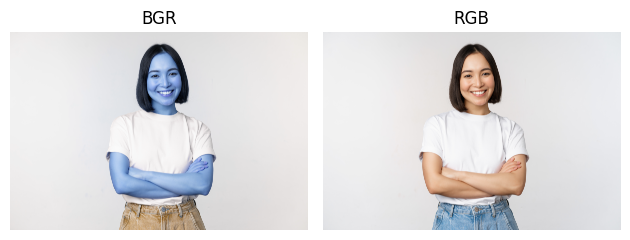

In [1]:
import cv2 as cv
import matplotlib.pyplot as plt

# Membaca gambar
image = cv.imread('smile.jpg')
image_rgb = cv.cvtColor(image, cv.COLOR_BGR2RGB)

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title('BGR')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(image_rgb)
plt.title('RGB')
plt.axis('off')

plt.tight_layout()
plt.show()

In [2]:
cv.imwrite('hasil_gambar.jpg', image)
print("Gambar berhasil disimpan!")

Gambar berhasil disimpan!


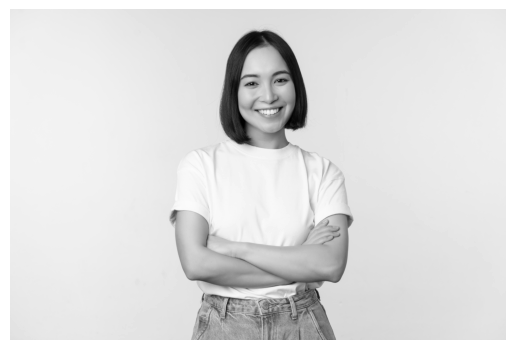

In [3]:
# Konversi gambar ke grayscale
gray_image = cv.cvtColor(image, cv.COLOR_BGR2GRAY)

# Menampilkan gambar grayscale
plt.imshow(gray_image, cmap='gray')
plt.axis('off')
plt.show()

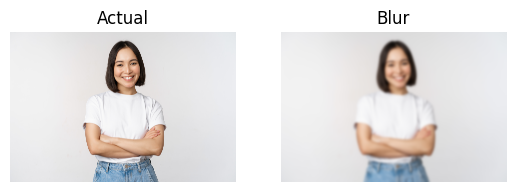

In [17]:
blurred_image = cv.GaussianBlur(image, (201, 201), 0)

plt.subplot(1, 2, 1)
plt.imshow(cv.cvtColor(image, cv.COLOR_BGR2RGB))
plt.title('Actual')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv.cvtColor(blurred_image, cv.COLOR_BGR2RGB))
plt.title('Blur')
plt.axis('off')

plt.show()

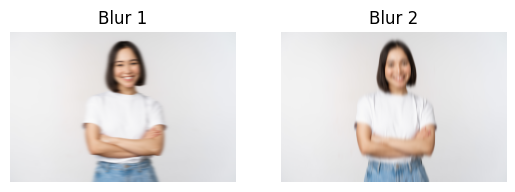

In [5]:
blurred_image1 = cv.GaussianBlur(image, (301, 31), 0)
blurred_image2 = cv.GaussianBlur(image, (31, 301), 0)

plt.subplot(1, 2, 1)
plt.imshow(cv.cvtColor(blurred_image1, cv.COLOR_BGR2RGB))
plt.title('Blur 1')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv.cvtColor(blurred_image2, cv.COLOR_BGR2RGB))
plt.title('Blur 2')
plt.axis('off')

plt.show()

In [ ]:
blurred_image = cv.GaussianBlur(image, (15, 15), 2.6)

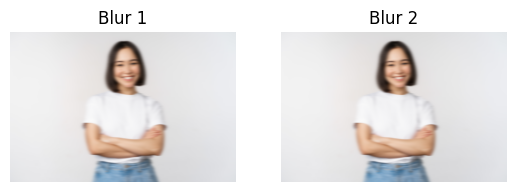

In [6]:
blurred_image = cv.GaussianBlur(image, (301, 31), sigmaX=45.5, sigmaY = 5)
blurred_image2 = cv.GaussianBlur(image, (301, 31), 0)

plt.subplot(1, 2, 1)
plt.imshow(cv.cvtColor(blurred_image, cv.COLOR_BGR2RGB))
plt.title('Blur 1')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv.cvtColor(blurred_image2, cv.COLOR_BGR2RGB))
plt.title('Blur 2')
plt.axis('off')

plt.show()

In [7]:
import numpy as np

print(np.array_equal(blurred_image, blurred_image2))

True


In [8]:
if np.array_equal(blurred_image, blurred_image2):
    print("Kedua hasil blur SAMA.")
else:
    print("Kedua hasil blur BERBEDA.")

Kedua hasil blur SAMA.


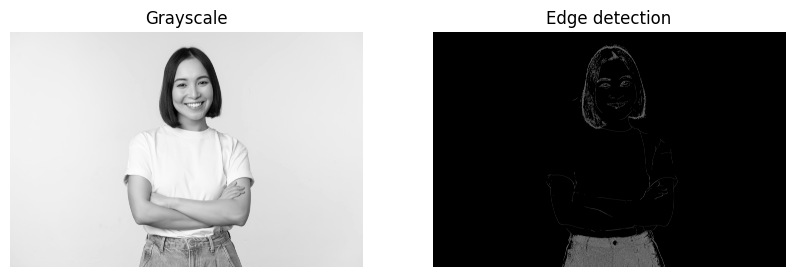

In [9]:
gray_image = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
edges = cv.Canny(gray_image, 100, 200)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(gray_image, cmap='gray')
plt.title('Grayscale')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(edges, cmap='gray')
plt.title('Edge detection')
plt.axis('off')

plt.show()

In [10]:
import numpy as np

median_intensity = np.median(gray_image)

lower_threshold = int(0.5 * median_intensity)
upper_threshold = int(1.5 * median_intensity)

edges = cv.Canny(gray_image, lower_threshold, upper_threshold)
print(f"Lower Threshold: {lower_threshold}, Upper Threshold: {upper_threshold}")


Lower Threshold: 115, Upper Threshold: 345


Threshold optimal otsu : 166.0
Lower Threshold: 83.0, Upper Threshold: 249.0


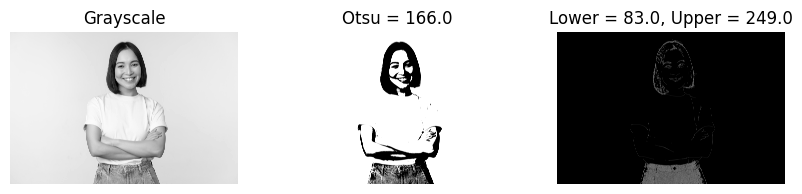

In [11]:
threshold, hist_image = cv.threshold(gray_image, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)

lower_threshold = 0.5 * threshold
upper_threshold = 1.5 * threshold

edges = cv.Canny(gray_image, int(lower_threshold), int(upper_threshold))

print(f"Threshold optimal otsu : {threshold}")
print(f"Lower Threshold: {lower_threshold}, Upper Threshold: {upper_threshold}")

plt.figure(figsize=(10, 5))

plt.subplot(1, 3, 1)
plt.imshow(gray_image, cmap='gray')
plt.title('Grayscale')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(hist_image, cmap='gray')
plt.title(f'Otsu = {threshold}')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(edges, cmap='gray')
plt.title(f'Lower = {lower_threshold}, Upper = {upper_threshold}')
plt.axis('off')

plt.show()

Transofrmasi Gambar

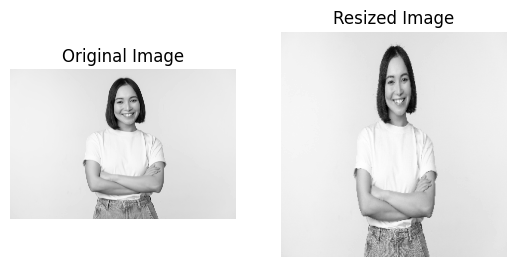

In [12]:
resized_image = cv.resize(gray_image, (300, 300))

plt.subplot(1, 2, 1)
plt.imshow(gray_image, cmap="gray")
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(resized_image, cmap="gray")
plt.title('Resized Image')
plt.axis('off')

plt.show()


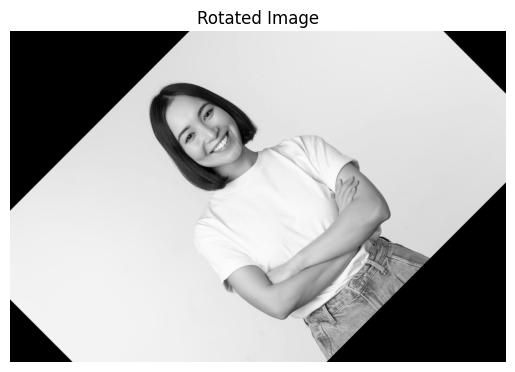

In [13]:
(h, w) = gray_image.shape[:2]
center = (w // 2, h // 2)

rotation_matrix = cv.getRotationMatrix2D(center, 45, 1.0)
rotated_image = cv.warpAffine(gray_image, rotation_matrix, (w, h))

plt.imshow(rotated_image, cmap="gray")
plt.title('Rotated Image')
plt.axis('off')
plt.show()


- h // 4 = 20 / 4 = 5
- h / 4 = 20 / 4 = 5.0

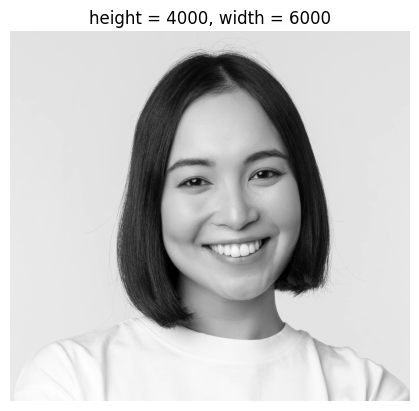

In [14]:
h, w = gray_image.shape
cropped_image = gray_image[150:2000, 2000:4000]

plt.imshow(cropped_image, cmap="gray")
plt.title(f"height = {h}, width = {w}")
plt.axis('off')
plt.show()


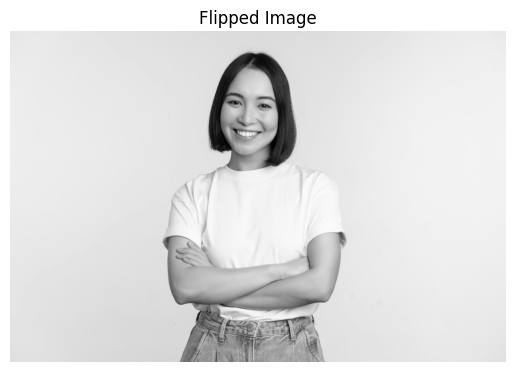

In [15]:
# Membalik gambar secara horizontal
flipped_image = cv.flip(gray_image, 1)

plt.imshow(flipped_image, cmap="gray")
plt.title('Flipped Image')
plt.axis('off')
plt.show()


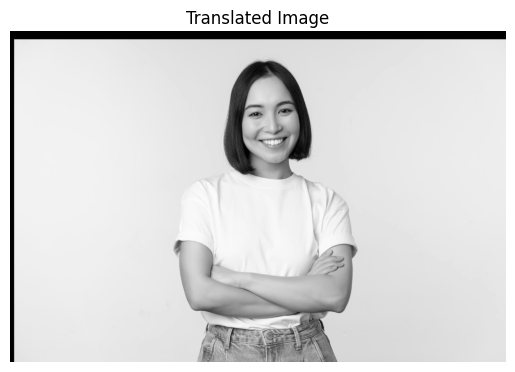

In [16]:
translation_matrix = np.float32([[1, 0, 50], [0, 1, 100]])
shifted_image = cv.warpAffine(gray_image, translation_matrix, (gray_image.shape[1], gray_image.shape[0]))

plt.imshow(shifted_image, cmap="gray")
plt.title('Translated Image')
plt.axis('off')
plt.show()
